<a href="https://colab.research.google.com/github/hollunacy/Concurrent-Computing/blob/main/%D0%9F%D0%9E%D0%9F%D0%92_%D0%9F%D0%A03_1_%D0%A7%D0%B0%D0%BD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import time
import threading

import pandas as pd

import matplotlib.pyplot as plt
import networkx as nx

#  Задание 1: Разминка для мозгов



```
for i in range(3, 7):
  y[i] = y[i-3] + z[i]
```



In [ ]:
unrolling =[]

for i in range(3, 10):
  unrolling.append({
      'operation': f"O{i}",
      'command': f"y[{i}] = y[{i-3}] + z[{i}]",
      'actions': f"read y[{i-3}], read z[{i}], write y[{i}]",
      'determinant': f"O{i-3}" if i-3 in range(3,7) else None
  })

pd.DataFrame(unrolling)

,operation,command,actions,determinant
0,O3,y[3] = y[0] + z[3],"read y[0], read z[3], write y[3]",None
1,O4,y[4] = y[1] + z[4],"read y[1], read z[4], write y[4]",None
2,O5,y[5] = y[2] + z[5],"read y[2], read z[5], write y[5]",None
3,O6,y[6] = y[3] + z[6],"read y[3], read z[6], write y[6]",O3
4,O7,y[7] = y[4] + z[7],"read y[4], read z[7], write y[7]",O4
5,O8,y[8] = y[5] + z[8],"read y[5], read z[8], write y[8]",O5
6,O9,y[9] = y[6] + z[9],"read y[6], read z[9], write y[9]",O6


In [ ]:
def visualize_dependency(unrolling):
  plt.figure(figsize=(3, 2))

  dependency_graph = nx.DiGraph()
  dependency_graph.add_nodes_from([i['operation'] for i in unrolling])
  dependencies = []

  independents = 0
  for i in unrolling:
    if i['determinant'] != None: dependencies.append((i['determinant'], i['operation']))
    else : independents += 1
  dependency_graph.add_edges_from(dependencies)

  def generate_positions(graph, columns=5):
    pos = {}
    for index, node in enumerate(graph.nodes()):
      row = index // columns
      col = index % columns
      pos[node] = (col, -row)
    return pos

  nx.draw(dependency_graph, generate_positions(dependency_graph, independents), with_labels=True, node_color="white", arrows=True)
  plt.show()

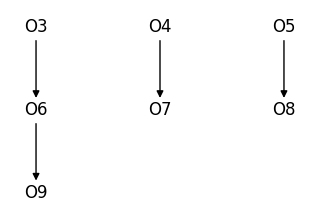

In [ ]:
visualize_dependency(unrolling)

In [ ]:
def get_layers(unrolling):
  layers = []

  iterations = unrolling.copy()
  layer_num = 1
  while True:
    layer = []
    iterations_remaining = iterations.copy()
    for iter in iterations:
      if iter['determinant'] not in [i['operation'] for i in iterations]:
        layer.append(iter['operation'])
        iterations_remaining.remove(iter)
    layers.append({
        'layer': layer_num,
        'operations': layer
    })

    iterations = iterations_remaining.copy()
    if not iterations: break
    layer_num +=1

  return layers

In [ ]:
pd.DataFrame(get_layers(unrolling))

,layer,operations
0,1,"[O3, O4, O5]"
1,2,"[O6, O7, O8]"
2,3,[O9]


# Задание 2: Проверка рук

In [ ]:
def print_result(title, result=None, time=0, speedup=None, status=False, efficiency=None):
  result_to_print = f"\tResult: {result:.4f}" if result else ""
  time_to_print = f"\tTime: {time:.4f} ms"
  speedup_to_print = f"\tSpeedup: {speedup:.2f}x" if speedup else ""
  status_to_print = (" 🟢 Faster" if speedup > 1 else " 🟠 Slower") if status else ""
  efficiency_to_print = f"\tEfficiency: {efficiency:.1f}%" if efficiency else ""
  print(title, result_to_print, time_to_print, speedup_to_print, status_to_print, efficiency_to_print)

In [ ]:
def compute_chunk(a, b, c, d, start, end):
    for i in range(start, end):
        d[i] = a[i] * b[i] + c[i]

size = 1_000_000
a = [2] * size
b = [3] * size
c = [4] * size
d = [0] * size

d_seq = [0] * size
time_start = time.perf_counter()
for i in range(size):
    d_seq[i] = a[i] * b[i] + c[i]
time_seq = (time.perf_counter() - time_start) * 1000
print_result("Sequential:", time=time_seq)

num_threads = 4
chunk_size = size // num_threads
threads = []

time_start = time.perf_counter()
for i in range(num_threads):
    start = i * chunk_size
    end = size if i == num_threads - 1 else (i + 1) * chunk_size
    t = threading.Thread(target=compute_chunk, args=(a, b, c, d, start, end))
    threads.append(t)
    t.start()
for t in threads: t.join()
time_par = (time.perf_counter() - time_start) * 1000
print_result("Parallel:", time=time_par, speedup=time_seq/time_par, status=True)

Sequential:  	Time: 241.2278 ms   
Parallel:  	Time: 87.9122 ms 	Speedup: 2.74x  🟢 Faster 


# Задание 3: Стань архитектором

In [ ]:
visualize_dependency(unrolling)

In [ ]:
pd.DataFrame(get_layers(unrolling))